# Week 2 — Feature Engineering: Airline Passenger Satisfaction

**Course:** MSc Machine Learning · **Team:** Group 1 — Team 22

**Data:** `data/raw/airline_passenger_satisfaction.csv` — `129,880 × 24` → 22 features + target `Satisfaction` (`Satisfied` → 1, `Neutral or Dissatisfied` → 0)

**Protocol:** `random_state=42` everywhere · stratified 80/20 split · 5-fold `StratifiedKFold` · primary metric ROC-AUC (+ PR-AUC, F1)

## 1. Team & Roles

| Member | Student ID | Role |
|---|---|---|
| Alisher Toxanbayev | 26MD0376 | Feature Engineer |
| Arsen Zhexenbiyev | 22MD0361 | Modelling Lead & Deployment Lead *(merged per 3-member team guidelines)* |
| Kamila Muzanbekova | 26MD0368 | Report Lead |

## 2. Feature Summary Table

The table covers all **24 raw columns** and the **engineered features**, and is placed before any modelling code. Each row has a decision from `{keep, transform, encode, remove, create, target}`, the `ColumnTransformer` branch that does the work, and the reason for this dataset. Level shares are from the full CSV. All fitted statistics (medians, scalers, variance filter) are learned on `X_train` only, inside the pipeline. The numeric `X_train` profile (skew, zero %, NaN) is printed in §3, right after the split.

### 2.1 Raw columns (24)

| # | Feature | Type / domain | Decision | CT branch → implementation | Output column(s) | Justification (this dataset) |
|---|---|---|---|---|---|---|
| 1 | `ID` | Integer, unique per row | **Remove** | Dropped before the split | — | Row key with no predictive signal; keeping it would let the model memorise rows |
| 2 | `Satisfaction` | Binary string: `Neutral or Dissatisfied` 56.55% / `Satisfied` 43.45% | **Target** | Stateless map `Satisfied → 1`, else `0`, before the split | `y` | Mild imbalance → stratified 80/20 split and PR-AUC reported alongside ROC-AUC |
| 3 | `Gender` | Nominal: `Female` 50.7% / `Male` 49.3% | **Encode** | `nominal` → `OneHotEncoder(drop="first", handle_unknown="ignore")` | `Gender_Male` | Balanced binary; `drop="first"` avoids the dummy trap in LR |
| 4 | `Customer Type` | Nominal: `Returning` 81.7% / `First-time` 18.3% | **Encode** | `nominal` (as above) | `Customer Type_Returning` | Loyalty is a plausible satisfaction driver; the smallest level is well above 1% |
| 5 | `Type of Travel` | Nominal: `Business` 69.1% / `Personal` 30.9% | **Encode** | `nominal` (as above) | `Type of Travel_Personal` | Kept as one named column so SQ2 (business vs personal drivers) can be read from SHAP |
| 6 | `Class` | Ordinal: `Economy` 44.9% / `Economy Plus` 7.2% / `Business` 47.9% | **Encode** | `class_ord` → `OrdinalEncoder([["Economy","Economy Plus","Business"]], unknown_value=-1)` | `Class` (0/1/2) | Service tiers are ordered; one column keeps the order without three dummies |
| 7 | `Age` | Continuous, symmetric (skew ≈ 0.00) | **Keep** | `age` → median `SimpleImputer` → `RobustScaler` | `Age` | Not skewed, so no transform; scaled so LR coefficients are comparable |
| 8 | `Flight Distance` | Continuous > 0, right-skewed (skew 1.11, min 31, no zeros) | **Transform** | `log_skewed` → median `SimpleImputer` → `log1p` → `RobustScaler` | `log1p_Flight Distance` | Compresses the long-haul tail; LR is linear in x |
| 9 | `Departure Delay` | Minutes ≥ 0, heavy tail (skew 6.83, 56.5% zeros) | **Transform** (+ feeds row 25) | `log_skewed` (as above) | `log1p_Departure Delay` | `log1p` compresses the tail and keeps exact zeros at 0; the delay effect on log-odds is concave |
| 10 | `Arrival Delay` | Minutes ≥ 0; the only column with NaNs (321 in `X_train`, 0.31%); r = 0.966 with `Departure Delay` | **Remove** (raw) → feeds row 25 | Consumed by `net_delay`; no raw output | — | The only pair with \|r\| > 0.90; dropping the raw column removes the redundancy and keeps the information |
| 11 | `Departure and Arrival Time Convenience` | Likert 0–5 (`0` = not applicable) | **Keep** | `likert` → median `SimpleImputer` → `RobustScaler` | same name | Scheduling touchpoint; the 0-rate is above 1%, so its flag survives (row 27) |
| 12 | `Ease of Online Booking` | Likert 0–5 | **Keep** | `likert` | same name | Digital touchpoint; r = 0.715 with Wifi (below 0.90), so both stay and selection decides |
| 13 | `Check-in Service` | Likert 0–5 | **Keep** | `likert` | same name | Ground-service touchpoint; no 0s in train, so its flag is constant and dropped |
| 14 | `Online Boarding` | Likert 0–5 | **Keep** | `likert` | same name | Digital touchpoint; expected strong signal; its flag survives |
| 15 | `Gate Location` | Likert 0–5 | **Keep** | `likert` | same name | Airport-layout touchpoint; its flag is constant on train and dropped |
| 16 | `On-board Service` | Likert 0–5 | **Keep** | `likert` | same name | Cabin-crew touchpoint |
| 17 | `Seat Comfort` | Likert 0–5 | **Keep** | `likert` | same name | Comfort touchpoint; r 0.61–0.69 with Cleanliness (kept, RFECV candidate); its flag is constant on train and dropped |
| 18 | `Leg Room Service` | Likert 0–5 | **Keep** | `likert` | same name | Comfort touchpoint, likely tied to `Class` |
| 19 | `Cleanliness` | Likert 0–5 | **Keep** | `likert` | same name | r 0.61–0.69 with Entertainment and Seat Comfort; below threshold, so kept |
| 20 | `Food and Drink` | Likert 0–5 | **Keep** | `likert` | same name | Catering touchpoint |
| 21 | `In-flight Service` | Likert 0–5 | **Keep** | `likert` | same name | Cabin-crew touchpoint |
| 22 | `In-flight Wifi Service` | Likert 0–5 | **Keep** | `likert` | same name | Digital touchpoint; a 0 often means wifi was not offered, so its flag survives |
| 23 | `In-flight Entertainment` | Likert 0–5 | **Keep** | `likert` | same name | Comfort touchpoint; correlated with Cleanliness (0.61–0.69, kept) |
| 24 | `Baggage Handling` | Likert 0–5 | **Keep** | `likert` | same name | Ground-service touchpoint; its flag is constant on train and dropped |

*Likert note:* the 14 ratings are ordinal scores, so they stay numeric (no one-hot). The median imputer is defensive, since none has NaNs. `0` means *not applicable*, not a low rating, so row 27 handles it separately.

### 2.2 Engineered features

| # | Feature | Type | Decision | CT branch → implementation | Output | Justification (this dataset) |
|---|---|---|---|---|---|---|
| 25 | `Net Delay Recovery` | Continuous; `Departure Delay − Arrival Delay` (minutes recovered in flight; skew −2.92, can be negative) | **Create** | `net_delay` → `DelayFeatureEngineer(impute_strategy="net_median")` → `PowerTransformer("yeo-johnson", standardize=False)` → `RobustScaler` | `Net Delay Recovery` | Resolves r = 0.966 and keeps the recovery signal. A missing `Arrival Delay` gets the **train median of the difference**, not of arrival (see deviation 4). Yeo-Johnson, unlike Box-Cox, accepts negative values |
| 26 | `log1p_Flight Distance`, `log1p_Departure Delay` | Continuous | **Transform** (rows 8–9) | `FunctionTransformer(np.log1p, feature_names_out=log1p_names)` | 2 cols | Stateless, so it cannot leak; the name function is defined at module level so `joblib` can pickle it |
| 27 | `<Likert>_is_na` × 14 | Binary float `(x == 0)` | **Create** + filter | `likert_flags` → `LikertZeroFlagger` → `VarianceThreshold(0.0099)` | **4 kept:** `Departure and Arrival Time Convenience_is_na`, `Ease of Online Booking_is_na`, `In-flight Wifi Service_is_na`, `Online Boarding_is_na` | Gives "not used" rows their own intercept, so each rating's slope is fit on real 1–5 scores. The threshold 0.0099 = p(1−p) at p = 1%: below about 1,000 positives in train, LR coefficients are unstable. **10 flags removed:** 4 are constant on train (`Check-in Service`, `Gate Location`, `Seat Comfort`, `Baggage Handling`) and 6 have prevalence < 1% (`On-board Service`, `Leg Room Service`, `Cleanliness`, `Food and Drink`, `In-flight Service`, `In-flight Entertainment`). The per-flag evidence is in §5 |

**Width:** 22 columns before selection (3 OHE + 1 ordinal + 1 age + 2 log + 1 net delay + 14 Likert), plus 4 flags = **26 columns** (S4). §9 reduces this to **≤ 20**, so predictive PCA is not needed (§10).

### 2.3 Deviations from the Week 1 proposal

| # | Week 1 proposal | Week 2 (this notebook) | Reason |
|---|---|---|---|
| 1 | 23 input features | **22 features** | `ID` is a key and `Satisfaction` is the target: 24 − 2 = 22 |
| 2 | Likert block assumed > 0.90 collinear | **Not collinear**: the highest Likert pair is r = 0.715 (Ease of Booking ↔ Wifi) | Measured on `X_train`; all Likert columns kept, selection decides |
| 3 | `Flight Distance` treated as zero-inflated | **Skewed but not zero-inflated** (min 31) | Plain `log1p`, no zero-indicator |
| 4 | Impute `Arrival Delay` with its raw median | **Impute the net difference** with its train median (`net_median`) | Both medians are 0, but 83 of the 321 NaN-arrival train rows have `Departure Delay > 54`. Arrival-median imputation would give them up to +530 min recovery, far above the observed train max of +54. Tested in S1 vs S1b |
| 5 | Keep all 14 `*_is_na` flags | **Only 4 of 14 survive** `VarianceThreshold(0.0099)` | 10 are constant or < 1% prevalent on train (row 27) |
| 6 | Default `LogisticRegression()` | `LogisticRegression(max_iter=1000, random_state=42)` | The default `max_iter=100` does not converge on the scaled 26-column matrix |
| 7 | PCA / UMAP considered for modelling | **t-SNE for visualisation only**; no PCA or UMAP in the predictive pipeline | N_final ≤ 20 keeps named features for SQ2 SHAP; `umap-learn` is not installed |

## 3. Setup, Load, Split & `X_train` Numeric Profile

In [1]:
# Cell 1 — paths, imports & constants
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA_PATH = ROOT / "data" / "raw" / "airline_passenger_satisfaction.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Fallback: use the CSV at the repo root if data/raw/ does not exist
if not DATA_PATH.exists() and (ROOT / DATA_PATH.name).exists():
    DATA_PATH = ROOT / DATA_PATH.name
    print(f"NOTE: data/raw/ not found, using legacy location {DATA_PATH}")

RANDOM_STATE = 42
TARGET = "Satisfaction"

CLASS_ORDER = ["Economy", "Economy Plus", "Business"]
NOMINAL_COLS = ["Gender", "Customer Type", "Type of Travel"]
ORDINAL_COLS = ["Class"]
CATEGORICAL_COLS = NOMINAL_COLS + ORDINAL_COLS
CAT_DOMAINS = {
    "Gender": {"Female", "Male"},
    "Customer Type": {"First-time", "Returning"},
    "Type of Travel": {"Business", "Personal"},
    "Class": set(CLASS_ORDER),
}
CONTINUOUS_COLS = ["Age", "Flight Distance", "Departure Delay", "Arrival Delay"]
LIKERT_COLS = [
    "Departure and Arrival Time Convenience", "Ease of Online Booking", "Check-in Service",
    "Online Boarding", "Gate Location", "On-board Service", "Seat Comfort",
    "Leg Room Service", "Cleanliness", "Food and Drink", "In-flight Service",
    "In-flight Wifi Service", "In-flight Entertainment", "Baggage Handling",
]
NUMERIC_COLS = CONTINUOUS_COLS + LIKERT_COLS  # 18 numerics
# The 22 raw features in CSV order (ID and Satisfaction removed)
FEATURE_COLS = [
    "Gender", "Age", "Customer Type", "Type of Travel", "Class",
    "Flight Distance", "Departure Delay", "Arrival Delay", *LIKERT_COLS,
]
assert len(FEATURE_COLS) == 22 and len(LIKERT_COLS) == 14 and len(NUMERIC_COLS) == 18

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

print(f"ROOT      : {ROOT}")
print(f"DATA_PATH : {DATA_PATH}")
print(f"FIG_DIR   : {FIG_DIR}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

NOTE: data/raw/ not found, using legacy location c:\Users\Kamila\Desktop\Airline Passenger Sat\ML-project\airline_passenger_satisfaction.csv
ROOT      : c:\Users\Kamila\Desktop\Airline Passenger Sat\ML-project
DATA_PATH : c:\Users\Kamila\Desktop\Airline Passenger Sat\ML-project\airline_passenger_satisfaction.csv
FIG_DIR   : c:\Users\Kamila\Desktop\Airline Passenger Sat\ML-project\reports\figures
Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | matplotlib 3.11.0 | seaborn 0.13.2


In [2]:
# Load the raw CSV, drop the ID key and map the target (stateless, so safe before the split)
df = pd.read_csv(DATA_PATH)
assert df.shape == (129_880, 24), f"unexpected shape {df.shape}"
assert df["ID"].is_unique, "ID is not a unique key"
assert set(df[TARGET].unique()) == {"Satisfied", "Neutral or Dissatisfied"}, "unexpected target labels"

X = df.drop(columns=["ID", TARGET])
y = (df[TARGET] == "Satisfied").astype(int).rename(TARGET)

print(f"Raw CSV : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"X       : {X.shape[0]:,} rows x {X.shape[1]} features | y positive rate (Satisfied) = {y.mean():.4f}")

Raw CSV : 129,880 rows x 24 columns
X       : 129,880 rows x 22 features | y positive rate (Satisfied) = 0.4345


In [3]:
# Pre-split schema check on raw X. Stateless: it reads no statistics, so it
# cannot leak. The same function is reused by the Week 4 app to validate user input.
def validate_raw_features(X: pd.DataFrame) -> None:
    """Assert the 22-column order, known categorical domains, Likert in {0..5}, NaNs only in Arrival Delay."""
    assert list(X.columns) == FEATURE_COLS, (
        f"column order mismatch: {[c for c in X.columns if c not in FEATURE_COLS] or list(X.columns)}"
    )
    for col, domain in CAT_DOMAINS.items():
        unknown = set(X[col].dropna().unique()) - domain
        assert not unknown, f"{col}: unknown levels {sorted(unknown)}"
    for col in NUMERIC_COLS:
        assert pd.api.types.is_numeric_dtype(X[col]), f"{col} is not numeric ({X[col].dtype})"
    for col in LIKERT_COLS:
        vals = X[col].dropna()
        assert vals.isin(range(6)).all(), f"{col}: values outside {{0..5}}: {sorted(set(vals) - set(range(6)))}"
    nan_cols = X.columns[X.isna().any()].tolist()
    assert set(nan_cols) <= {"Arrival Delay"}, f"unexpected NaNs in {sorted(set(nan_cols) - {'Arrival Delay'})}"


validate_raw_features(X)
print("Schema check passed:")
print(f"  - 22 columns in the expected order")
print(f"  - categorical domains: " + "; ".join(f"{c} = {sorted(d)}" for c, d in CAT_DOMAINS.items()))
print(f"  - 14 Likert columns, all values in {{0..5}}")
print(f"  - NaNs only in: {X.columns[X.isna().any()].tolist()}")

Schema check passed:
  - 22 columns in the expected order
  - categorical domains: Gender = ['Female', 'Male']; Customer Type = ['First-time', 'Returning']; Type of Travel = ['Business', 'Personal']; Class = ['Business', 'Economy', 'Economy Plus']
  - 14 Likert columns, all values in {0..5}
  - NaNs only in: ['Arrival Delay']


In [4]:
# Split FIRST: every statistic, plot and fit below uses X_train only; X_test is touched only in §13
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
assert (len(X_train), len(X_test)) == (103_904, 25_976)
assert X_train.index.intersection(X_test.index).empty

# Drop the full-data objects so no later cell can compute a statistic on them by accident
del df, X, y

print(f"X_train {X_train.shape} | X_test {X_test.shape}")
print(f"Positive rate (Satisfied): train {y_train.mean():.4f} | test {y_test.mean():.4f}")

X_train (103904, 22) | X_test (25976, 22)
Positive rate (Satisfied): train 0.4345 | test 0.4345


In [5]:
# X_train numeric profile: skew, zero %, NaN (feeds the Feature Summary Table in §2)
num_train = X_train[NUMERIC_COLS]
profile = pd.DataFrame({
    "block": ["continuous"] * len(CONTINUOUS_COLS) + ["likert"] * len(LIKERT_COLS),
    "min": num_train.min(),
    "median": num_train.median(),
    "mean": num_train.mean(),
    "max": num_train.max(),
    "std": num_train.std(),
    "skew": num_train.skew(),
    "zero %": num_train.eq(0).mean() * 100,
    "NaN": num_train.isna().sum(),
    "NaN %": num_train.isna().mean() * 100,
})
display(profile.round({"median": 2, "mean": 2, "std": 2, "skew": 2, "zero %": 2, "NaN %": 2}))

assert profile.loc[profile["NaN"] > 0].index.tolist() == ["Arrival Delay"]
assert profile.loc["Flight Distance", "min"] > 0, "Flight Distance has zeros (not expected)"
print(f"NaN in Arrival Delay: {profile.loc['Arrival Delay', 'NaN']:,} rows "
      f"({profile.loc['Arrival Delay', 'NaN %']:.2f}% of X_train)")
print(f"Flight Distance: min {profile.loc['Flight Distance', 'min']:.0f}, "
      f"skew {profile.loc['Flight Distance', 'skew']:.2f} -> skewed but not zero-inflated")
print(f"Departure Delay: skew {profile.loc['Departure Delay', 'skew']:.2f}, "
      f"{profile.loc['Departure Delay', 'zero %']:.1f}% zeros")
print(f"Age: skew {profile.loc['Age', 'skew']:.2f}")

,block,min,median,mean,max,std,skew,zero %,NaN,NaN %
Age,continuous,7.0,40.0,39.40,85.0,15.15,-0.00,0.00,0,0.00
Flight Distance,continuous,31.0,844.0,1190.50,4983.0,998.04,1.11,0.00,0,0.00
Departure Delay,continuous,0.0,0.0,14.72,1592.0,38.24,6.83,56.48,0,0.00
Arrival Delay,continuous,0.0,0.0,15.08,1584.0,38.61,6.70,56.04,321,0.31
Departure and Arrival Time Convenience,likert,0.0,3.0,3.06,5.0,1.53,-0.34,5.17,0,0.00
Ease of Online Booking,likert,0.0,3.0,2.76,5.0,1.40,-0.02,4.37,0,0.00
Check-in Service,likert,1.0,3.0,3.31,5.0,1.27,-0.37,0.00,0,0.00
Online Boarding,likert,0.0,3.0,3.25,5.0,1.35,-0.46,2.39,0,0.00
Gate Location,likert,1.0,3.0,2.98,5.0,1.28,-0.06,0.00,0,0.00
On-board Service,likert,0.0,4.0,3.38,5.0,1.29,-0.42,0.00,0,0.00


NaN in Arrival Delay: 321 rows (0.31% of X_train)
Flight Distance: min 31, skew 1.11 -> skewed but not zero-inflated
Departure Delay: skew 6.83, 56.5% zeros
Age: skew -0.00


## 4. Custom Transformers & Verification

## 5. Variance Analysis

In [6]:
# 5a. Numeric variance on X_train (raw scale, ddof=1)
num_var = (
    X_train[NUMERIC_COLS].var()
    .to_frame("variance")
    .assign(block=lambda d: np.where(d.index.isin(LIKERT_COLS), "likert", "continuous"))
    .sort_values("variance")
)
display(num_var.round(4))

likert_var = num_var.loc[num_var["block"] == "likert", "variance"]
print(f"Smallest numeric variance: {num_var.index[0]} (var = {num_var['variance'].iloc[0]:.4f})")
print(f"Likert variance range    : {likert_var.min():.4f} ({likert_var.idxmin()}) "
      f"to {likert_var.max():.4f} ({likert_var.idxmax()})")
print("No numeric column has near-zero variance -> all 18 numerics are kept.")

,variance,block
In-flight Service,1.3843,likert
Baggage Handling,1.3937,likert
Check-in Service,1.6047,likert
Gate Location,1.6330,likert
On-board Service,1.6551,likert
Cleanliness,1.7269,likert
Leg Room Service,1.7331,likert
Seat Comfort,1.7402,likert
Food and Drink,1.7652,likert
In-flight Wifi Service,1.7653,likert


Smallest numeric variance: In-flight Service (var = 1.3843)
Likert variance range    : 1.3843 (In-flight Service) to 2.3342 (Departure and Arrival Time Convenience)
No numeric column has near-zero variance -> all 18 numerics are kept.


In [7]:
# 5b. Candidate Likert `*_is_na` flags: prevalence and variance on X_train.
# The flag is the stateless rule (x == 0) used by LikertZeroFlagger. Variance uses ddof=0 to
# match VarianceThreshold; the threshold 0.0099 = p(1 - p) at p = 1% (~1,000 positive rows).
VT_THRESHOLD = 0.0099

flags = X_train[LIKERT_COLS].eq(0).astype(float)
flag_tbl = pd.DataFrame({
    "flag": [f"{c}_is_na" for c in LIKERT_COLS],
    "positive rows": flags.sum().astype(int).values,
    "prevalence %": (flags.mean() * 100).values,
    "variance": flags.var(ddof=0).values,
})
flag_tbl["decision"] = np.where(flag_tbl["variance"] > VT_THRESHOLD, "Keep", "Remove")
flag_tbl["reason"] = np.select(
    [flag_tbl["decision"] == "Keep", flag_tbl["positive rows"] == 0],
    ["Above threshold", "Constant on train"],
    default="Prevalence < 1%",
)
flag_tbl = flag_tbl.sort_values("variance", ascending=False).reset_index(drop=True)
display(flag_tbl.round({"prevalence %": 3, "variance": 5}))

kept_flags = flag_tbl.loc[flag_tbl["decision"] == "Keep", "flag"].tolist()
expected_kept = {
    "Departure and Arrival Time Convenience_is_na", "Ease of Online Booking_is_na",
    "In-flight Wifi Service_is_na", "Online Boarding_is_na",
}
assert set(kept_flags) == expected_kept, f"kept flags changed: {kept_flags}"
print(f"{len(kept_flags)} of 14 flags survive VarianceThreshold({VT_THRESHOLD}): {kept_flags}")
print(f"Removed: {(flag_tbl['reason'] == 'Constant on train').sum()} constant on train, "
      f"{(flag_tbl['reason'] == 'Prevalence < 1%').sum()} with prevalence < 1%")

,flag,positive rows,prevalence %,variance,decision,reason
0,Departure and Arrival Time Convenience_is_na,5377,5.175,0.04907,Keep,Above threshold
1,Ease of Online Booking_is_na,4538,4.367,0.04177,Keep,Above threshold
2,In-flight Wifi Service_is_na,3128,3.010,0.02920,Keep,Above threshold
3,Online Boarding_is_na,2481,2.388,0.02331,Keep,Above threshold
4,Leg Room Service_is_na,474,0.456,0.00454,Remove,Prevalence < 1%
5,Food and Drink_is_na,104,0.100,0.00100,Remove,Prevalence < 1%
6,In-flight Entertainment_is_na,14,0.013,0.00013,Remove,Prevalence < 1%
7,Cleanliness_is_na,11,0.011,0.00011,Remove,Prevalence < 1%
8,On-board Service_is_na,3,0.003,0.00003,Remove,Prevalence < 1%
9,In-flight Service_is_na,3,0.003,0.00003,Remove,Prevalence < 1%


4 of 14 flags survive VarianceThreshold(0.0099): ['Departure and Arrival Time Convenience_is_na', 'Ease of Online Booking_is_na', 'In-flight Wifi Service_is_na', 'Online Boarding_is_na']
Removed: 4 constant on train, 6 with prevalence < 1%


In [8]:
# 5c. Categorical level frequencies on X_train (merge/drop rule: any level < 1%)
cat_freq = pd.concat(
    {
        col: X_train[col].value_counts().to_frame("count")
             .assign(**{"share %": lambda d: d["count"] / len(X_train) * 100})
        for col in CATEGORICAL_COLS
    },
    names=["feature", "level"],
)
display(cat_freq.round({"share %": 2}))

rarest = cat_freq["share %"].idxmin()
print(f"Smallest level: {rarest[0]} = {rarest[1]} at {cat_freq['share %'].min():.2f}% of X_train")
assert cat_freq["share %"].min() >= 1.0, "a categorical level is below 1%"
print("No level falls below 1% -> no level is merged or dropped.")

count  share %
feature        level                       
Gender         Female        52730    50.75
               Male          51174    49.25
Customer Type  Returning     84797    81.61
               First-time    19107    18.39
Type of Travel Business      71725    69.03
               Personal      32179    30.97
Class          Business      49699    47.83
               Economy       46612    44.86
               Economy Plus   7593     7.31

Smallest level: Class = Economy Plus at 7.31% of X_train
No level falls below 1% -> no level is merged or dropped.


### 5.1 Interpretation — Variance decisions

**Numeric variance (`X_train`).** The `.var()` table shows no numeric column with near-zero variance: the smallest is `In-flight Service` (var = 1.3843), so all numerics stay. The Likert block has variances in 1.3843–2.3342, so each rating carries real spread.

**Likert `*_is_na` flags.** The threshold 0.0099 = p(1 − p) at p = 1%, i.e. fewer than ~1,000 positive train rows, below which LR coefficients are unstable.

| Flag (`<Likert>_is_na`) | Prevalence (train) | Variance | Decision | Reason |
|---|---|---|---|---|
| `Departure and Arrival Time Convenience_is_na` | 5.175% | 0.04907 | **Keep** | Above threshold |
| `Ease of Online Booking_is_na` | 4.367% | 0.04177 | **Keep** | Above threshold |
| `In-flight Wifi Service_is_na` | 3.010% | 0.02920 | **Keep** | Above threshold; 0 often means wifi not offered |
| `Online Boarding_is_na` | 2.388% | 0.02331 | **Keep** | Above threshold |
| `Check-in Service_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `Gate Location_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `Seat Comfort_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `Baggage Handling_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `On-board Service_is_na` | 0.003% | 0.00003 | **Remove** | Prevalence < 1% (3 positive rows) |
| `Leg Room Service_is_na` | 0.456% | 0.00454 | **Remove** | Prevalence < 1% (474 positive rows) |
| `Cleanliness_is_na` | 0.011% | 0.00011 | **Remove** | Prevalence < 1% (11 positive rows) |
| `Food and Drink_is_na` | 0.100% | 0.00100 | **Remove** | Prevalence < 1% (104 positive rows) |
| `In-flight Service_is_na` | 0.003% | 0.00003 | **Remove** | Prevalence < 1% (3 positive rows) |
| `In-flight Entertainment_is_na` | 0.013% | 0.00013 | **Remove** | Prevalence < 1% (14 positive rows) |

**Categorical levels.** No level falls below 1%: the smallest is `Class = Economy Plus` at 7.31% of `X_train`, so no level is merged or dropped.

**Takeaway.** 4 of 14 flags survive `VarianceThreshold(0.0099)`. S4 (§8) checks that dropping the other 10 costs no ROC-AUC.

## 6. Correlation Analysis & Decision Table

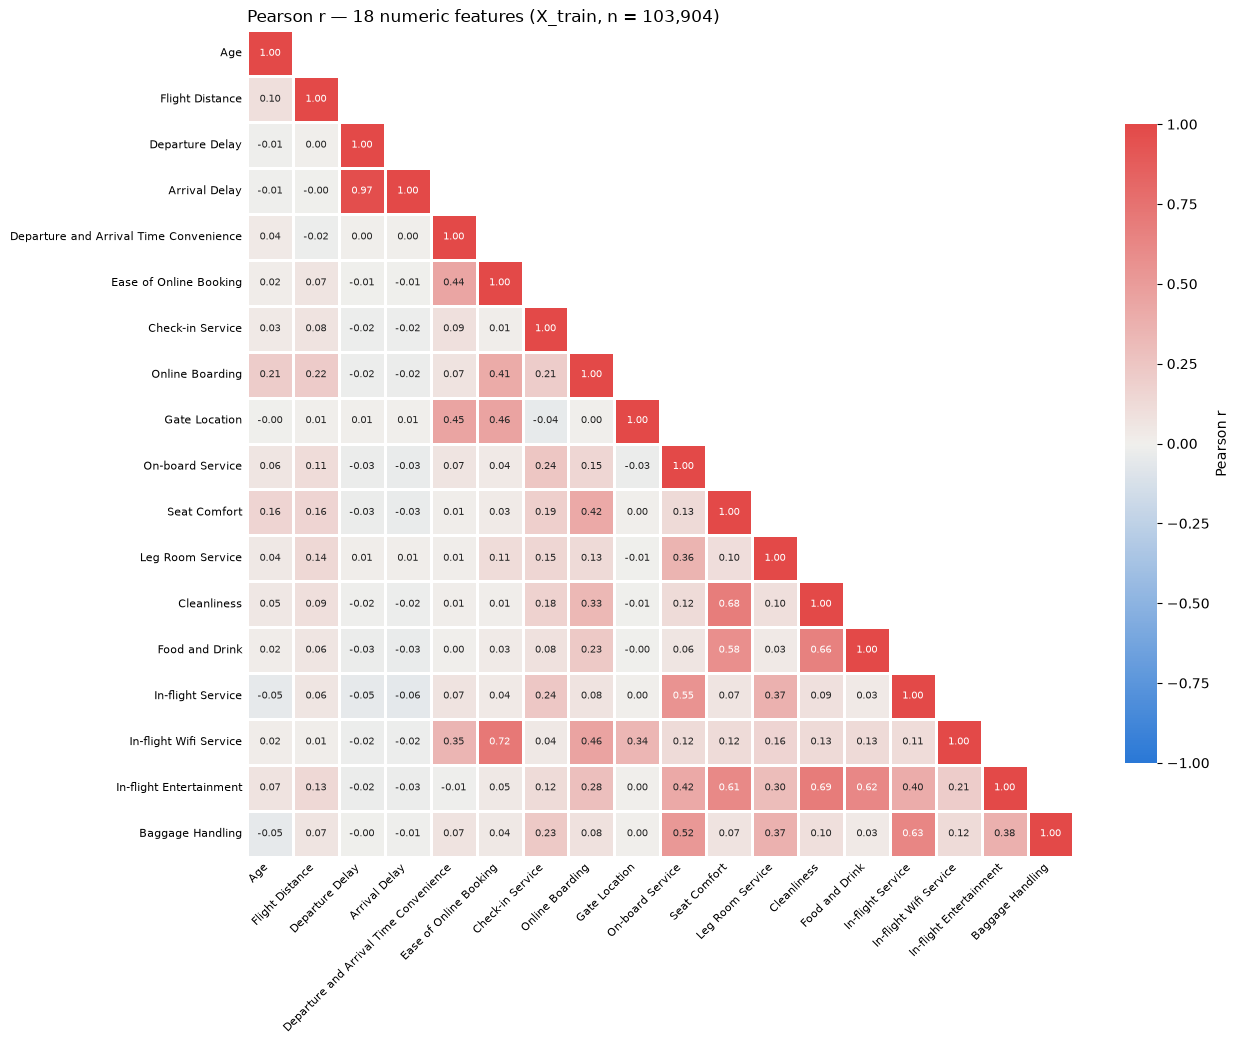

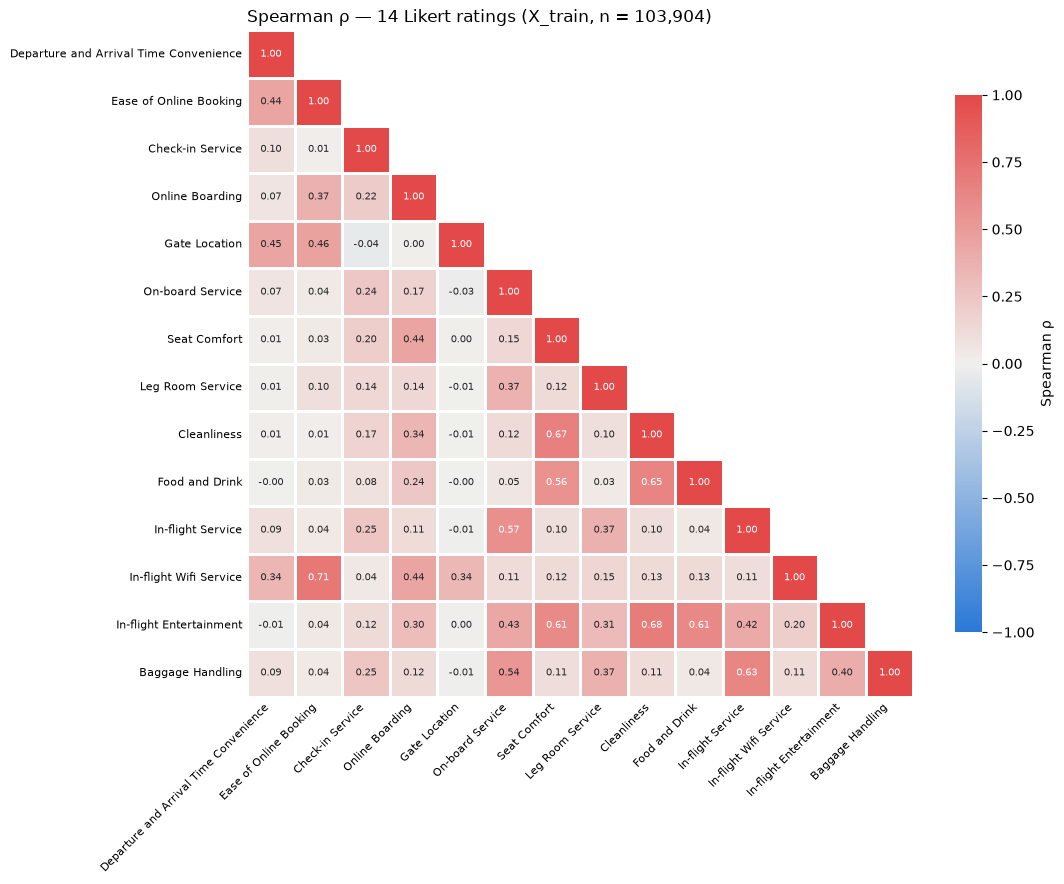

In [9]:
# 6a. Pearson (18 numerics) and Spearman (14 Likert, ordinal) correlation on X_train.
# pandas uses pairwise-complete rows, so the 321 NaNs in Arrival Delay are skipped, not imputed.
pearson = X_train[NUMERIC_COLS].corr(method="pearson")
spearman = X_train[NUMERIC_COLS].corr(method="spearman")

# Diverging blue <-> red with a neutral grey midpoint at r = 0
CORR_CMAP = LinearSegmentedColormap.from_list("corr_div", ["#2a78d6", "#f0efec", "#e34948"])


def plot_corr(r: pd.DataFrame, title: str, label: str, fname: str, figsize) -> None:
    mask = np.triu(np.ones_like(r, dtype=bool), k=1)  # lower triangle + diagonal
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        r, mask=mask, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0,
        annot=True, fmt=".2f", annot_kws={"size": 7},
        linewidths=1, linecolor="white", square=True,
        cbar_kws={"label": label, "shrink": 0.7}, ax=ax,
    )
    ax.set_title(title, fontsize=12, loc="left")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    ax.tick_params(length=0)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


plot_corr(pearson, f"Pearson r — 18 numeric features (X_train, n = {len(X_train):,})",
          "Pearson r", "week2_corr_pearson_numeric.png", (13, 11))
plot_corr(spearman.loc[LIKERT_COLS, LIKERT_COLS],
          f"Spearman ρ — 14 Likert ratings (X_train, n = {len(X_train):,})",
          "Spearman ρ", "week2_corr_spearman_likert.png", (11, 9.5))

In [10]:
# 6b. Programmatic pair scan on the Pearson matrix (Spearman shown alongside)
iu = np.triu_indices(len(NUMERIC_COLS), k=1)
pairs = pd.DataFrame({
    "feature_1": pearson.columns[iu[0]],
    "feature_2": pearson.columns[iu[1]],
    "pearson_r": pearson.values[iu],
    "spearman_rho": spearman.values[iu],
})
pairs["|r|"] = pairs["pearson_r"].abs()
pairs["|rho - r|"] = (pairs["spearman_rho"] - pairs["pearson_r"]).abs()
pairs["both Likert"] = pairs["feature_1"].isin(LIKERT_COLS) & pairs["feature_2"].isin(LIKERT_COLS)
pairs = pairs.sort_values("|r|", ascending=False).reset_index(drop=True)

high = pairs[pairs["|r|"] > 0.90]
moderate = pairs[(pairs["|r|"] > 0.60) & (pairs["|r|"] <= 0.90)]
cols_show = ["feature_1", "feature_2", "pearson_r", "spearman_rho", "|rho - r|", "both Likert"]

print(f"Pairs with |r| > 0.90: {len(high)}")
display(high[cols_show].round(3))
print(f"Pairs with 0.60 < |r| <= 0.90: {len(moderate)} "
      f"({moderate['both Likert'].sum()} inside the Likert block)")
display(moderate[cols_show].round(3))
print(f"Max |Spearman - Pearson| over the moderate pairs: {moderate['|rho - r|'].max():.3f}")

top_likert = pairs[pairs["both Likert"]].iloc[0]
print(f"Strongest Likert pair: {top_likert['feature_1']} <-> {top_likert['feature_2']} "
      f"(r = {top_likert['pearson_r']:.3f}, rho = {top_likert['spearman_rho']:.3f})")

assert len(high) == 1 and set(high.iloc[0][["feature_1", "feature_2"]]) == {"Departure Delay", "Arrival Delay"}, \
    "expected exactly one |r| > 0.90 pair: Departure Delay <-> Arrival Delay"

Pairs with |r| > 0.90: 1


,feature_1,feature_2,pearson_r,spearman_rho,|rho - r|,both Likert
0,Departure Delay,Arrival Delay,0.966,0.739,0.227,False


Pairs with 0.60 < |r| <= 0.90: 7 (7 inside the Likert block)


,feature_1,feature_2,pearson_r,spearman_rho,|rho - r|,both Likert
1,Ease of Online Booking,In-flight Wifi Service,0.716,0.712,0.004,True
2,Cleanliness,In-flight Entertainment,0.693,0.682,0.011,True
3,Seat Comfort,Cleanliness,0.680,0.668,0.012,True
4,Cleanliness,Food and Drink,0.657,0.646,0.011,True
5,In-flight Service,Baggage Handling,0.630,0.631,0.001,True
6,Food and Drink,In-flight Entertainment,0.624,0.611,0.012,True
7,Seat Comfort,In-flight Entertainment,0.613,0.605,0.008,True


Max |Spearman - Pearson| over the moderate pairs: 0.012
Strongest Likert pair: Ease of Online Booking <-> In-flight Wifi Service (r = 0.716, rho = 0.712)


### 6.1 Interpretation — Correlation decisions

**Pairs with |r| > 0.90 (Pearson, `X_train`).** The programmatic scan finds 1 pair: `Departure Delay` ↔ `Arrival Delay`, r = 0.966. No Likert pair comes close to the threshold.

**Pairs with 0.60 < |r| ≤ 0.90.** 7 pairs, all inside the Likert block. The strongest is `Ease of Online Booking` ↔ `In-flight Wifi Service` (Pearson 0.716, Spearman 0.712). Spearman values are within 0.012 of Pearson, so the ordinal scale does not change any decision.

| Pair | r (train, Pearson) | ρ (train, Spearman) | Decision | Reason |
|---|---|---|---|---|
| `Departure Delay` ↔ `Arrival Delay` | 0.966 | 0.739 | **Combine** into `Net Delay Recovery`, drop raw `Arrival Delay` | Keeps the in-flight recovery signal, removes redundancy |
| `Ease of Online Booking` ↔ `In-flight Wifi Service` | 0.716 | 0.712 | **Keep both** | Below 0.90; distinct digital touchpoints, so selection decides |
| `Cleanliness` ↔ `In-flight Entertainment` | 0.693 | 0.682 | **Keep both** | Below 0.90; RFECV removal candidate (SQ1) |
| `Seat Comfort` ↔ `Cleanliness` | 0.680 | 0.668 | **Keep both** | Below 0.90; RFECV removal candidate (SQ1) |
| `Cleanliness` ↔ `Food and Drink` | 0.657 | 0.646 | **Keep both** | Below 0.90 |
| `In-flight Service` ↔ `Baggage Handling` | 0.630 | 0.631 | **Keep both** | Below 0.90 |
| `Food and Drink` ↔ `In-flight Entertainment` | 0.624 | 0.611 | **Keep both** | Below 0.90 |
| `Seat Comfort` ↔ `In-flight Entertainment` | 0.613 | 0.605 | **Keep both** | Below 0.90 |

**Post-engineering check (S2 matrix).** The highest remaining pair is [...] ↔ [...] at |r| = [...], so no pair exceeds 0.90. `log1p_Departure Delay` ↔ `Net Delay Recovery` is r = [...], which confirms the net feature is not a re-encoding of departure delay.

## 7. Ablation S0 — Baseline

<!-- Placeholder: replace every [...] with the value printed by the code cell directly above. -->

### 7.1 Interpretation — S0 Baseline

S0 fits LR on the raw 22 features (median impute → `RobustScaler`, OHE / ordinal) with both delay columns present, giving ROC-AUC [...] ± [...], PR-AUC [...] ± [...] and F1 [...] ± [...]. The train ROC-AUC is [...], a gap of [...] to validation, so the linear baseline does not overfit. The score is already high because the Likert touchpoints carry most of the signal, so later steps should be judged against the fold noise (paired Δ std), not against absolute size. Fit time is [...] s per fold, the reference for SQ1 latency.

## 8. Ablation S1, S1b, S2–S4

<!-- Placeholder: replace every [...] with the value printed by the code cell directly above. -->

### 8.1 Interpretation — S1 Collinearity (`Net Delay Recovery`)

S1 replaces raw `Arrival Delay` with `Net Delay Recovery` (`net_median` → Yeo-Johnson → `RobustScaler`). ROC-AUC moves from [...] to [...] (Δ = [...] vs paired std [...]) → **[...]**. The fold-to-fold std of the delay coefficients falls from [...] (S0) to [...] (S1), which shows the collinearity fix stabilises the coefficients even if the score barely changes. This is expected: r = 0.966 inflates coefficient variance, not predictive power.

### 8.2 Note — S1 vs S1b (imputation strategy)

With `arrival_median` imputation (S1b), ROC-AUC is [...] vs [...] for `net_median` (Δ = [...], paired std [...]), and the max imputed recovery is [...] min vs [...] min. Because only 321 train rows are affected the score gap is [...], so `net_median` is kept because it avoids impossible recovery values above the observed train max of +54 min.

### 8.3 Interpretation — S2 Skew (`log1p`)

S2 applies `log1p` to `Flight Distance` and `Departure Delay`. ROC-AUC moves from [...] (S1) to [...] (Δ = [...] vs paired std [...]) → **[...]**; PR-AUC Δ = [...]. [...] This matches / does not match the hypothesis that the delay → log-odds response is concave, so compressing the tail should help a model that is linear in x.

### 8.4 Interpretation — S3 Likert flags (all 14)

S3 adds all 14 `*_is_na` flags unfiltered (36 columns). ROC-AUC moves from [...] to [...] (Δ = [...] vs paired std [...]) → **[...]**. The largest absolute flag coefficients are [...], [...] and [...], consistent with the hypothesis that the gain comes from Wifi / Online Boarding / Ease of Booking, where 0 means "not used". Separating "not applicable" from a low rating lets each rating's slope be fit on real 1–5 scores.

### 8.5 Interpretation — S4 Near-zero-variance filter

S4 adds `VarianceThreshold(0.0099)` to the flag branch, cutting width from 36 to 26 columns. ROC-AUC moves from [...] to [...] (Δ = [...] vs paired std [...]) → **[...]**, and fit time changes from [...] s to [...] s. Removing the 10 constant or < 1% flags costs no measurable signal, which confirms the §5 variance decisions with CV evidence.

## 9. Feature Selection — Method A vs Method B: Comparison, Stability & Decision

<!-- Placeholder: replace every [...] with the value printed by the code cell directly above. -->

### 9.1 Interpretation — Feature selection: Method A vs Method B

**S5a — `SelectKBest(mutual_info_classif)`.** The one-std rule picks k = [...] (best k = [...] at ROC-AUC [...]; threshold [...]). Outer CV gives ROC-AUC [...] ± [...], so it is **[...]** vs S4 (Δ = [...], paired std [...]).

**S5b — `CappedRFECV`.** Inner CV selects [...] features (cap 20; uncapped optimum [...]). Outer CV gives ROC-AUC [...] ± [...], **[...]** vs S4 (Δ = [...], paired std [...]). Note that the `|coef|` ranking reflects mixed scales (IQR-scaled continuous vs 0/1 flags).

| Method | # selected | Selected | Removed | ROC-AUC | PR-AUC | F1 | Fit time / fold (s) | Jaccard |
|---|---|---|---|---|---|---|---|---|
| A — SelectKBest (MI) | [...] | [...] | [...] | [...] ± [...] | [...] ± [...] | [...] ± [...] | [...] | [...] |
| B — CappedRFECV | [...] | [...] | [...] | [...] ± [...] | [...] ± [...] | [...] ± [...] | [...] | [...] |

**Stability.** [...] features are selected in all 5 outer folds by both methods (e.g. [...]). Unstable features (selected in 1–4 folds) are [...]; they are the SQ1 candidates for removal with little loss.

**Decision.** Rule 1: the ROC-AUC gap is [...] vs paired std [...] → [...]. Rule 2 / 3: [...]. **`FINAL_SELECTOR` = [...]** with N = [...] ≤ 20 features.

## 10. Dimensionality Reduction — PCA Statement, EVR Diagnostic & t-SNE

<!-- Placeholder: replace every [...] with the value printed by the code cell directly above. -->

### 10.1 PCA statement & EVR diagnostic

**Predictive PCA is excluded.** N_final = [...] ≤ 20, so the pipeline is already compact. PCA would replace named features with orthogonal mixtures, which would break the named-feature SHAP analysis needed for SQ2 (business vs personal drivers) in Weeks 3–4.

**EVR diagnostic (not used by the model).** On the [...] selected features, [...] components are needed to reach 90% cumulative explained variance (n_90 = [...]). The first component alone explains [...]%. Because n_90 is close to N_final, the selected features are not redundant, and PCA would add little compression.

### 10.2 Interpretation — t-SNE (5,000-row stratified `X_train` subsample)

**Class separability.** In panel 1, `Satisfied` and `Neutral or Dissatisfied` passengers form [...] regions: [...] (e.g. large single-class areas / partially mixed areas), which is consistent with the high CV ROC-AUC of [...].

**Sub-clusters.** Panel 2 shows that `Type of Travel` drives [...] distinct sub-clusters: Business travellers concentrate in [...], while Personal travellers form [...], and the Personal cluster is predominantly [...] (dissatisfied / satisfied).

**Overlap.** The classes overlap mainly in [...], where passengers with mid-range ratings ([...]) sit between the two groups; this region is where most LR errors are expected.

**Implications for Week 3.** Because the satisfied and dissatisfied regions are [...] (largely separable / split into several sub-clusters with curved borders), a linear model should do [...], while tree ensembles (Random Forest, gradient boosting) may gain from [...] (interactions such as `Type of Travel` × service ratings). t-SNE preserves local neighbourhoods, not global distances, so cluster sizes and gaps are read qualitatively only.

## 11. Final Feature Set

## 12. Ablation Log Export

## 13. Final Pipeline — Fit, Transform & Predict